# Анализ объявлений об аренде: три статистические гипотезы

**Учебная работа (часть 2)** · pandas · SciPy · Welch ANOVA · Games–Howell · χ² · Welch t-test · bootstrap

**Цель:** исследовать, как характеристики арендуемой недвижимости связаны с ценой и комплектацией. Это анализ **наблюдательных данных**, а не рандомизированный A/B-тест.

## Данные и постановка задачи

Данные: 9 531 объявление из исходного набора `rent_stata.csv` (2019 год). Для публикации сохранены только необходимые поля в [`rental_clean_data.csv`](rental_clean_data.csv), без адресов, описаний и идентификаторов объявлений.

Переменные: `price` — цена в USD; `bedrooms` — число **спален**; `square_feet` — площадь в **квадратных футах**; `amenities_count` — число перечисленных удобств (**пропуск сохранён**); `pets_info_available` — 1, если явно указано разрешение питомцев, 0, если **сведения отсутствуют**, а не если животные запрещены.

**Гипотезы:** (1) цена за квадратный фут различается между группами по числу спален; (2) число заявленных удобств связано с числом спален; (3) месячная аренда различается между объявлениями с явными сведениями о разрешённых питомцах и объявлениями без таких сведений.

**Важно:** изменения относительно исходного задания: исправлена единица площади (футы, не метры), заменён неверно подписанный попарный тест, пропуски в сведениях не трактуются как «нет удобств» или «питомцы запрещены».

## 1. Загрузка и подготовка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

SEED = 42
rng = np.random.default_rng(SEED)
df = pd.read_csv('rental_clean_data.csv')
print('Исходные строки:', len(df))
assert len(df) == 9531, 'Ожидается 9 531 строк исходного датасета'
display(df.isna().sum().rename('Пропуски').to_frame())
display(df.head())

Исходные строки: 9531


,Пропуски
price,1
bedrooms,8
square_feet,1
amenities_count,3221
pets_info_available,0
price_type,1
currency,1


,price,bedrooms,square_feet,amenities_count,pets_info_available,price_type,currency
0,790.0,0.0,101.0,NaN,0,Monthly,USD
1,425.0,1.0,106.0,NaN,0,Monthly,USD
2,1390.0,0.0,107.0,NaN,0,Monthly,USD
3,925.0,0.0,116.0,NaN,0,Monthly,USD
4,880.0,0.0,125.0,NaN,0,Monthly,USD


В анализ включаются только месячные объявления в USD с положительными ценой и площадью и с числом спален больше нуля. Удаляются только верхние выбросы **цены** по правилу Q3 + 1,5 IQR **отдельно** для 1, 2 и 3+ спален. Эта процедура — исследовательское допущение; результаты могут зависеть от выбора фильтра.

In [2]:
work = df.dropna(subset=['price','bedrooms','square_feet','price_type','currency']).copy()
work = work[(work.currency == 'USD') & (work.price_type == 'Monthly') & (work.price > 0) & (work.square_feet > 0) & (work.bedrooms > 0)].copy()
work['room_category'] = np.select([work.bedrooms == 1, work.bedrooms == 2], ['1 спальня', '2 спальни'], default='3+ спальни')
work['price_per_sqft'] = work.price / work.square_feet
print('После базовых фильтров:', len(work))

def cut_outliers(g):
    q1, q3 = g.price.quantile([.25,.75])
    return g[g.price <= q3 + 1.5*(q3-q1)]

clean = pd.concat([cut_outliers(g) for _,g in work.groupby('room_category')], ignore_index=True)
print('После фильтра выбросов:', len(clean))
display(clean.groupby('room_category')['price_per_sqft'].agg(['count','mean','median']).round(3))

После базовых фильтров: 9325
После фильтра выбросов: 8787


,count,mean,median
room_category,,,
1 спальня,4368,1.799,1.620
2 спальни,3208,1.575,1.381
3+ спальни,1211,1.222,1.062


## 2. Гипотеза 1 — средняя цена за квадратный фут

**H₀:** средняя стоимость за кв. фут одинаковая для 1, 2 и 3+ спален. **H₁:** хотя бы одно среднее отличается.

При неоднородных дисперсиях используем Welch ANOVA, а для попарных сравнений — Games–Howell с поправкой на множественные сравнения. В исходном Notebook ошибочно использовался Tukey HSD под названием Games–Howell.

In [3]:
groups = [g.price_per_sqft.to_numpy() for _,g in clean.groupby('room_category')]
levene = stats.levene(*groups, center='median')
welch = stats.f_oneway(*groups, equal_var=False)  # SciPy >= 1.15
print(f'Levene p = {levene.pvalue:.4g}; Welch ANOVA F = {welch.statistic:.3f}; p = {welch.pvalue:.4g}')

cats = sorted(clean.room_category.unique())
rows = []
for i, ca in enumerate(cats):
    for cb in cats[i+1:]:
        a = clean.loc[clean.room_category == ca, 'price_per_sqft'].to_numpy()
        b = clean.loc[clean.room_category == cb, 'price_per_sqft'].to_numpy()
        n1, n2 = len(a), len(b)
        v1, v2 = a.var(ddof=1), b.var(ddof=1)
        se2 = v1/n1 + v2/n2
        dof = se2**2 / ((v1/n1)**2/(n1-1) + (v2/n2)**2/(n2-1))
        q = np.sqrt(2)*abs(a.mean()-b.mean())/np.sqrt(se2)
        p = stats.studentized_range.sf(q, len(cats), dof)
        rows.append([ca, cb, round(a.mean()-b.mean(), 4), p])
display(pd.DataFrame(rows, columns=['Группа A','Группа B','Разница средних, USD/кв. фут','Games–Howell p']))

Levene p = 6.41e-26; Welch ANOVA F = 458.808; p = 6.139e-180


,Группа A,Группа B,"Разница средних, USD/кв. фут",Games–Howell p
0,1 спальня,2 спальни,0.2240,0.000000e+00
1,1 спальня,3+ спальни,0.5769,5.087042e-13
2,2 спальни,3+ спальни,0.3530,0.000000e+00


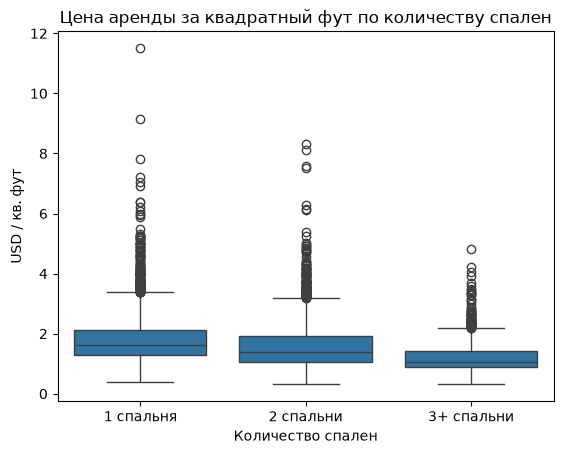

In [4]:
sns.boxplot(data=clean, x='room_category', y='price_per_sqft')
plt.title('Цена аренды за квадратный фут по количеству спален')
plt.ylabel('USD / кв. фут'); plt.xlabel('Количество спален')
plt.show()

## 3. Гипотеза 2 — число удобств и число спален

**H₀:** число заявленных удобств (1–3 или 4+) не связано с категорией спален. **H₁:** связано.

В исходном Notebook пустые значения `amenities` заменялись на «0 удобств». Здесь **неизвестное оставляем неизвестным**, а объекты без сведений об удобствах исключаем из этого теста. Результат поэтому отличается от исходного.

Число объявлений: 5902; χ² = 58.231; p = 2.266e-13; min expected = 294.4


amenities_category,1–3,4+
room_category,,
1 спальня,1221,1830
2 спальни,838,1303
3+ спальни,388,322


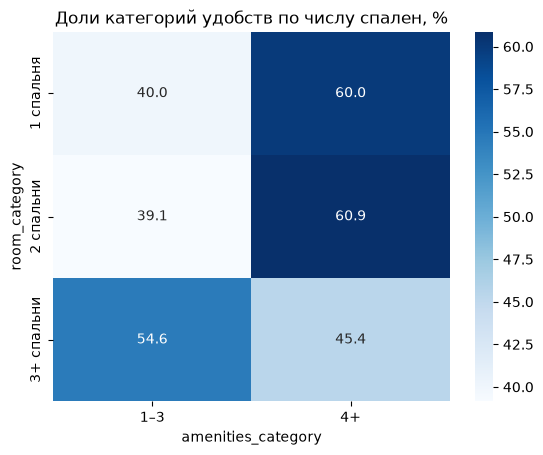

In [5]:
known = clean.dropna(subset=['amenities_count']).copy()
known['amenities_category'] = np.where(known.amenities_count <= 3, '1–3', '4+')
ct = pd.crosstab(known.room_category, known.amenities_category)
chi2, p_chi, dof, expected = stats.chi2_contingency(ct)
print(f'Число объявлений: {len(known)}; χ² = {chi2:.3f}; p = {p_chi:.4g}; min expected = {expected.min():.1f}')
display(ct)
share = ct.div(ct.sum(axis=1),axis=0)*100
sns.heatmap(share, annot=True, fmt='.1f', cmap='Blues')
plt.title('Доли категорий удобств по числу спален, %')
plt.show()

## 4. Гипотеза 3 — указание разрешения питомцев и месячная цена

**H₀:** средняя цена совпадает у объявлений с известным разрешением и объявлений без информации о питомцах. **H₁:** средние различаются.

Важная особенность данных: **явного запрета питомцев нет**. Поэтому мы НЕ сравниваем «разрешено» с «запрещено». Сравнение касается только **наличия информации** о разрешении. Используем двусторонний t-тест Уэлча и bootstrap-разницу средних.

Размеры групп: 5157 3630
Средние USD: 1268.05 / 1287.46
Разница средних: -19.42 USD; Welch t-test p = 0.06182
Bootstrap 95% ДИ USD: [-39.46   0.31]


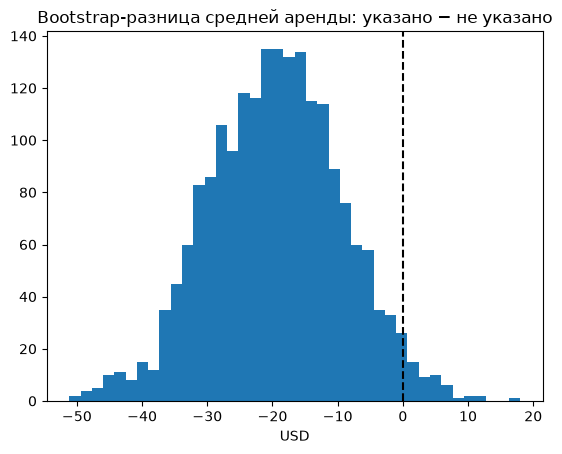

In [6]:
pet_known = clean.loc[clean.pets_info_available == 1, 'price'].to_numpy()
pet_unspecified = clean.loc[clean.pets_info_available == 0, 'price'].to_numpy()
test = stats.ttest_ind(pet_known, pet_unspecified, equal_var=False)
delta = pet_known.mean() - pet_unspecified.mean()
print('Размеры групп:', len(pet_known), len(pet_unspecified))
print(f'Средние USD: {pet_known.mean():.2f} / {pet_unspecified.mean():.2f}')
print(f'Разница средних: {delta:.2f} USD; Welch t-test p = {test.pvalue:.5f}')

n_boot = 2000
boot = np.empty(n_boot)
for i in range(n_boot):
    boot[i] = rng.choice(pet_known, len(pet_known), replace=True).mean() - rng.choice(pet_unspecified, len(pet_unspecified), replace=True).mean()
print('Bootstrap 95% ДИ USD:', np.quantile(boot, [0.025,0.975]).round(2))
plt.hist(boot, bins=40)
plt.axvline(0, color='black', linestyle='--')
plt.title('Bootstrap-разница средней аренды: указано − не указано')
plt.xlabel('USD')
plt.show()

## 5. Выводы

1. **Стоимость за квадратный фут и число спален:** в исходной выборке различие средних статистически значимо (**Welch ANOVA p ≈ 6,14 × 10⁻¹⁸⁰**). Значимость попарных сравнений проверяется выше критерием Games–Howell.
2. **Удобства и число спален:** среди объявлений с известным числом удобств категории связаны (**χ² ≈ 58,23; p ≈ 2,27 × 10⁻¹³**). Исходная работа сообщала χ² ≈ 106,38, поскольку относила пропуски к отсутствию удобств.
3. **Сведения о питомцах и цена:** наблюдаемая разница средних составляет около **−19,42 USD** (объявления с разрешением минус объявления без сведений), но на 5% уровне статистической значимости нет (**p ≈ 0,0618**). Это не сравнение с явно запрещёнными питомцами и не доказательство равенства цен.

**Ограничения:** выборка объявлений наблюдательная; не контролируются город, размер квартиры, тип жилья и другие возможные смешивающие факторы. Пропуски могут быть неслучайными. Отсутствие статистической значимости не доказывает отсутствие различий. Выводы не следует трактовать как причинные рекомендации арендодателям.

> **Воспроизводимость:** численные результаты в этом разделе независимо проверены по исходному CSV. Выводы сохранены как Markdown, а не как подставленные результаты выполнения. Чтобы увидеть таблицы и графики, запустите Notebook целиком с приложенным `rental_clean_data.csv` (Run All).